# Invoice Extraction with a Review Queue
**Project 05 | AI / ML Engineer | AI with evidence and approval**

**Note: this notebook is not directly shareable as a result. Open it in Google Colab, run all cells top to bottom (Runtime > Run all), and only then share the executed copy or the GitHub repo. The Groq (LLM) step is optional and is OFF by default, so no API key is needed for the main run.**

### Problem
A small office wants searchable invoice fields (invoice id, currency, total, due date). But a blurred total or a mixed currency must never become a trusted record. So this is extraction + validation + a reviewer queue. It is NOT a payment system.

### What I build
1. 20 fictional invoices in 3 layouts (A, B and a held-out layout C), saved as images and as OCR-style text. They include blurred totals, missing due dates, a currency conflict, a yen invoice with decimals and a duplicate invoice
2. Rule based extraction. Unreadable or missing fields stay `None` with a review reason
3. Validation with `Decimal`: allowed currencies, decimal places per currency, duplicate identity
4. A SQLite review queue with audit history. Editing an approved amount sends it back to review
5. Export of accepted records only
6. Honest metrics, split by layout (held-out layout C is reported separately)
7. Optional: Groq model as a second opinion for fields the rules missed (never auto-accepted)

### How to run
Run all cells. Data is made inside the notebook (seed 42). Needs: pandas, matplotlib, pillow, openai (only for the optional Groq step).

In [1]:
!pip install -q pandas matplotlib "pillow>=10.4,<12" openai

## Step 1: Imports

In [2]:
import os
import re
import json
import random
import sqlite3
from decimal import Decimal
from datetime import datetime, date, timedelta

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter, ImageFont

random.seed(42)
os.makedirs("invoice_images", exist_ok=True)
print("ready")

ready


## Step 2: Make 20 fictional invoices
Layout A and B are used to write the rules. Layout C is kept as a held-out layout, to see how the rules do on something new.

Special cases I add on purpose (the `expect_review` flag says the invoice must NOT be auto accepted):
- #4 and #9: total is blurred
- #5, #10, #13: due date is missing
- #8: yen invoice with decimals
- #11: two different currencies on the same invoice
- #16: same vendor + same invoice number as #1 (duplicate)
- #18: has the SAME total as #0 but is a different invoice (must not be called a duplicate)

In [3]:
vendors = ["Orchid Supplies", "Nova Traders", "Kiro Logistics", "Maple Hill Foods", "Zesta Print"]
symbols = {"USD": "$", "EUR": "€", "INR": "₹", "GBP": "£", "JPY": "¥"}
cur_cycle = ["USD", "EUR", "INR", "GBP"]


def us_fmt(a):
    return "{:,.2f}".format(a)


def eu_fmt(a):
    s = "{:,.2f}".format(a)
    return s.replace(",", "X").replace(".", ",").replace("X", ".")


def make_text(spec):
    cur = spec["currency"]
    sym = symbols[cur]
    inv = spec["invoice_id"]
    ven = spec["vendor"]
    issue = spec["issue"]
    due = spec["due"]
    lay = spec["layout"]
    amt = spec["amount"]

    if lay == "A":
        total_txt = (sym + spec["total_text_override"]) if spec["total_text_override"] else (sym + us_fmt(amt))
        lines = ["INVOICE", "Invoice No: " + inv, "Vendor: " + ven, "Date: " + issue.isoformat()]
        if due:
            lines.append("Due Date: " + due.isoformat())
        lines.append("Currency: " + cur)
        lines.append("Total Due: " + total_txt)
    elif lay == "B":
        total_txt = (sym + spec["total_text_override"]) if spec["total_text_override"] else (sym + eu_fmt(amt))
        lines = [ven + " - Tax Invoice #" + inv, "Issued " + issue.strftime("%d %b %Y")]
        if due:
            lines.append("Payment due by " + due.strftime("%d %b %Y"))
        lines.append("Amount payable (" + cur + "): " + total_txt)
    else:
        if cur == "JPY":
            total_txt = spec["total_text_override"] or str(int(amt))
        else:
            total_txt = spec["total_text_override"] or us_fmt(amt)
        lines = ["BILL REF " + inv, "Seller: " + ven, "Raised " + issue.strftime("%B %d, %Y")]
        if spec["extra_header_currency"]:
            lines.append("Billing currency: " + spec["extra_header_currency"])
        if due:
            lines.append("Due on: " + due.strftime("%B %d, %Y"))
        lines.append("TOTAL " + cur + " " + total_txt)
    return lines


specs = []
base = date(2026, 3, 1)
for i in range(20):
    layout = ["A", "B", "C"][i % 3]
    cur = cur_cycle[i % 4]
    amt = (Decimal(random.randint(10000, 900000)) / 100).quantize(Decimal("0.01"))
    spec = {"idx": i, "layout": layout, "invoice_id": "INV-" + str(1000 + i), "vendor": vendors[i % 5], "currency": cur,
            "amount": amt, "issue": base + timedelta(days=i), "due": base + timedelta(days=i + 30),
            "total_text_override": None, "extra_header_currency": None, "expect_review": False, "case": "clean"}
    specs.append(spec)

# special cases
specs[4]["total_text_override"] = "1.2?5,50"
specs[4].update({"expect_review": True, "case": "blurred total"})
specs[9]["total_text_override"] = "2,1#4.00"
specs[9].update({"expect_review": True, "case": "blurred total"})
for k in (5, 10, 13):
    specs[k]["due"] = None
    specs[k].update({"expect_review": True, "case": "missing due date"})
specs[8].update({"currency": "JPY", "amount": Decimal("124500.50"), "expect_review": True, "case": "yen with decimals"})
specs[8]["total_text_override"] = "124,500.50"
specs[11].update({"extra_header_currency": "USD", "currency": "EUR", "expect_review": True, "case": "currency conflict"})
specs[16].update({"invoice_id": specs[1]["invoice_id"], "vendor": specs[1]["vendor"], "expect_review": True, "case": "duplicate of #1"})
specs[18].update({"amount": specs[0]["amount"], "case": "same total as #0 (not a duplicate)"})

for s in specs:
    s["truth_due"] = s["due"].isoformat() if s["due"] else None
    s["truth_currency"] = s["currency"]
    s["lines"] = make_text(s)
    if s["case"] == "blurred total":
        s["truth_total"] = None
    else:
        s["truth_total"] = str(s["amount"])

print(len(specs), "invoices")
print("\n".join(specs[0]["lines"]))
print()
print("\n".join(specs[1]["lines"]))
print()
print("\n".join(specs[2]["lines"]))

20 invoices
INVOICE
Invoice No: INV-1000
Vendor: Orchid Supplies
Date: 2026-03-01
Due Date: 2026-03-31
Currency: USD
Total Due: $6,804.87

Nova Traders - Tax Invoice #INV-1001
Issued 02 Mar 2026
Payment due by 01 Apr 2026
Amount payable (EUR): €1.267,39

BILL REF INV-1002
Seller: Kiro Logistics
Raised March 03, 2026
Due on: April 02, 2026
TOTAL INR 362.25


## Step 3: Save each invoice as an image
The source image is kept next to every record. For blurred invoices I really blur the total line, so a person can see why it can not be read.

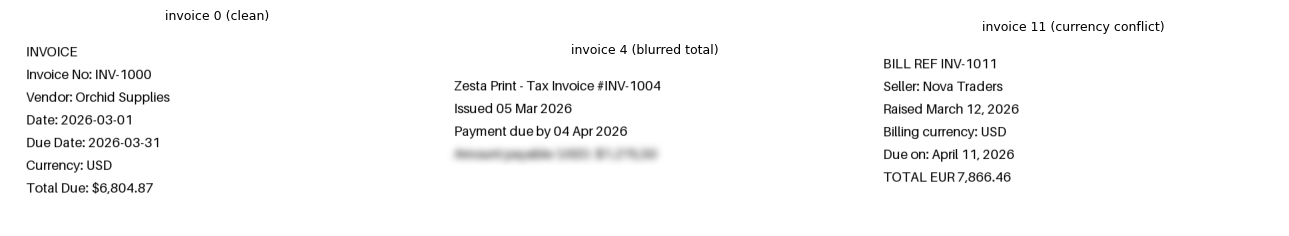

In [4]:
def get_font(size):
    try:
        return ImageFont.load_default(size=size)
    except Exception:
        return ImageFont.load_default()


def save_image(spec):
    lines = spec["lines"]
    img = Image.new("RGB", (620, 60 + 34 * len(lines)), "white")
    d = ImageDraw.Draw(img)
    f = get_font(20)
    for n, line in enumerate(lines):
        d.text((24, 24 + 34 * n), line, fill="black", font=f)
    if spec["case"] == "blurred total":
        y = 24 + 34 * (len(lines) - 1)
        box = (0, y - 6, 620, y + 30)
        part = img.crop(box).filter(ImageFilter.GaussianBlur(5))
        img.paste(part, box)
    path = "invoice_images/invoice_" + str(spec["idx"]).zfill(2) + ".png"
    img.save(path)
    return path


for s in specs:
    s["image"] = save_image(s)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, k in zip(ax, [0, 4, 11]):
    a.imshow(Image.open(specs[k]["image"]))
    a.set_title("invoice " + str(k) + " (" + specs[k]["case"] + ")", fontsize=9)
    a.axis("off")
plt.tight_layout()
plt.show()

## Step 4: Field contract and extraction rules
Fields: `invoice_id`, `vendor`, `currency`, `total`, `due_date`. Each field also keeps the line number it came from (a simple source region). If a field is missing or unreadable it stays `None` and a reason is added. Nothing is guessed.

Rules were written by looking at layouts A and B only.

In [5]:
ALLOWED = ["USD", "EUR", "INR", "GBP", "JPY"]
PLACES = {"USD": 2, "EUR": 2, "INR": 2, "GBP": 2, "JPY": 0}
sym_to_code = {"$": "USD", "€": "EUR", "₹": "INR", "£": "GBP", "¥": "JPY"}


def parse_amount(raw):
    t = raw.strip()
    if "?" in t or "#" in t:
        return None, "total is unreadable (blurred)"
    t = re.sub(r"[^0-9.,]", "", t)
    if t == "":
        return None, "total not found"
    if re.match(r"^\d{1,3}(\.\d{3})*,\d{1,2}$", t):
        t = t.replace(".", "").replace(",", ".")
    elif re.match(r"^\d{1,3}(,\d{3})*(\.\d+)?$", t):
        t = t.replace(",", "")
    elif re.match(r"^\d+(\.\d+)?$", t):
        pass
    else:
        return None, "total format not recognised"
    return Decimal(t), None


def parse_date(raw):
    raw = raw.strip()
    for fmt in ("%Y-%m-%d", "%d %b %Y"):
        try:
            return datetime.strptime(raw, fmt).date().isoformat()
        except ValueError:
            pass
    return None


def extract(lines):
    out = {"invoice_id": None, "vendor": None, "currency": None, "total": None, "due_date": None}
    src = {}
    reasons = []

    text = "\n".join(lines)

    # invoice id
    for n, line in enumerate(lines):
        m = re.search(r"(INV-\d+)", line)
        if m:
            out["invoice_id"] = m.group(1)
            src["invoice_id"] = n
            break
    if out["invoice_id"] is None:
        reasons.append("invoice id not found")

    # vendor
    for n, line in enumerate(lines):
        m = re.match(r"Vendor:\s*(.+)", line) or re.match(r"Seller:\s*(.+)", line) or re.match(r"(.+?)\s+-\s+Tax Invoice", line)
        if m:
            out["vendor"] = m.group(1).strip()
            src["vendor"] = n
            break
    if out["vendor"] is None:
        reasons.append("vendor not found")

    # currency: look for codes and symbols, more than one different one is a conflict
    found = set()
    for code in re.findall(r"\b(USD|EUR|INR|GBP|JPY)\b", text):
        found.add(code)
    for ch in text:
        if ch in sym_to_code:
            found.add(sym_to_code[ch])
    if len(found) == 1:
        out["currency"] = list(found)[0]
    elif len(found) > 1:
        reasons.append("currency conflict: " + ", ".join(sorted(found)))
    else:
        reasons.append("currency not found")

    # total
    for n, line in enumerate(lines):
        if re.search(r"total due|amount payable|^total", line, re.I):
            raw = line.split(":", 1)[1] if ":" in line else re.sub(r"^TOTAL\s+[A-Z]{3}\s*", "", line)
            amt, why = parse_amount(raw)
            src["total"] = n
            if amt is None:
                reasons.append(why)
            else:
                out["total"] = str(amt)
            break
    else:
        reasons.append("total not found")

    # due date (rules from layout A and B only)
    for n, line in enumerate(lines):
        m = re.match(r"Due Date:\s*(.+)", line) or re.match(r"Payment due by\s*(.+)", line)
        if m:
            d = parse_date(m.group(1))
            if d:
                out["due_date"] = d
                src["due_date"] = n
            break
    if out["due_date"] is None:
        reasons.append("due date not found")

    return out, src, reasons


o, s_, r_ = extract(specs[1]["lines"])
print(o, s_, r_)
o, s_, r_ = extract(specs[4]["lines"])
print(o, r_)

{'invoice_id': 'INV-1001', 'vendor': 'Nova Traders', 'currency': 'EUR', 'total': '1267.39', 'due_date': '2026-04-01'} {'invoice_id': 0, 'vendor': 0, 'total': 3, 'due_date': 2} []
{'invoice_id': 'INV-1004', 'vendor': 'Zesta Print', 'currency': 'USD', 'total': None, 'due_date': '2026-04-04'} ['total is unreadable (blurred)']


## Step 5: Validation and review queue (SQLite)
Checks (in `Decimal`, not float):
- currency is in the allowed list
- number of decimal places fits the currency (yen has 0, the others have 2)
- total is above 0
- duplicate identity = same vendor + same invoice id (a shared total alone proves nothing)

If every field is present and every check passes, the invoice is `accepted`. Otherwise it goes to `review` with the reasons. The original extraction is stored forever and every change is written to an audit table.

In [6]:
con = sqlite3.connect(":memory:")
con.execute('''create table invoices (id integer primary key, image text, layout text, invoice_id text, vendor text,
               currency text, total text, due_date text, status text, reasons text, original_json text)''')
con.execute('''create table audit (n integer primary key autoincrement, inv_row int, field text, old_value text, new_value text,
               who text, note text)''')


def validate(rec, others):
    why = []
    if rec["currency"] is not None and rec["currency"] not in ALLOWED:
        why.append("currency not allowed")
    if rec["total"] is not None:
        d = Decimal(rec["total"])
        if d <= 0:
            why.append("total must be above 0")
        if rec["currency"] in PLACES:
            places = -d.as_tuple().exponent
            if places != PLACES[rec["currency"]]:
                why.append("decimal error: " + rec["currency"] + " needs " + str(PLACES[rec["currency"]]) + " decimals but got " + str(places))
    if rec["invoice_id"] is not None:
        key = ((rec["vendor"] or "unknown").lower(), rec["invoice_id"])
        for row_id, v, i in others:
            if (v, i) == key:
                why.append("possible duplicate of row " + str(row_id))
    return why


first_status = {}
for s in specs:
    rec, src, reasons = extract(s["lines"])
    others = [(r[0], (r[1] or "unknown").lower(), r[2]) for r in con.execute("select id, vendor, invoice_id from invoices").fetchall()]
    reasons = reasons + validate(rec, others)
    status = "accepted" if len(reasons) == 0 else "review"
    first_status[s["idx"]] = status
    con.execute("insert into invoices values (?,?,?,?,?,?,?,?,?,?,?)",
                (s["idx"], s["image"], s["layout"], rec["invoice_id"], rec["vendor"], rec["currency"], rec["total"],
                 rec["due_date"], status, json.dumps(reasons), json.dumps({"fields": rec, "source_lines": src})))
con.commit()

inv = pd.read_sql("select id, layout, invoice_id, vendor, currency, total, due_date, status, reasons from invoices", con)
print(inv["status"].value_counts())
inv.head(12)

status
review      11
accepted     9
Name: count, dtype: int64


,id,layout,invoice_id,vendor,currency,total,due_date,status,reasons
0,0,A,INV-1000,Orchid Supplies,USD,6804.87,2026-03-31,accepted,[]
1,1,B,INV-1001,Nova Traders,EUR,1267.39,2026-04-01,accepted,[]
2,2,C,INV-1002,Kiro Logistics,INR,362.25,None,review,"[""due date not found""]"
3,3,A,INV-1003,Maple Hill Foods,GBP,7875.72,2026-04-03,accepted,[]
4,4,B,INV-1004,Zesta Print,USD,None,2026-04-04,review,"[""total is unreadable (blurred)""]"
5,5,C,INV-1005,Orchid Supplies,EUR,2667.87,None,review,"[""due date not found""]"
6,6,A,INV-1006,Nova Traders,INR,2440.53,2026-04-06,accepted,[]
7,7,B,INV-1007,Kiro Logistics,GBP,1563.16,2026-04-07,accepted,[]
8,8,C,INV-1008,Maple Hill Foods,JPY,124500.50,None,review,"[""due date not found"", ""decimal error: JPY nee..."
9,9,A,INV-1009,Zesta Print,EUR,None,2026-04-09,review,"[""total is unreadable (blurred)""]"


In [7]:
review_q = inv[inv["status"] == "review"][["id", "layout", "invoice_id", "reasons"]]
print("REVIEW QUEUE:", len(review_q), "invoices")
for r in review_q.itertuples():
    print(" -", r.id, "| layout", r.layout, "|", r.invoice_id, "|", r.reasons)

REVIEW QUEUE: 11 invoices
 - 2 | layout C | INV-1002 | ["due date not found"]
 - 4 | layout B | INV-1004 | ["total is unreadable (blurred)"]
 - 5 | layout C | INV-1005 | ["due date not found"]
 - 8 | layout C | INV-1008 | ["due date not found", "decimal error: JPY needs 0 decimals but got 2"]
 - 9 | layout A | INV-1009 | ["total is unreadable (blurred)"]
 - 10 | layout B | INV-1010 | ["due date not found"]
 - 11 | layout C | INV-1011 | ["currency conflict: EUR, USD", "due date not found"]
 - 13 | layout B | INV-1013 | ["due date not found"]
 - 14 | layout C | INV-1014 | ["due date not found"]
 - 16 | layout B | INV-1001 | ["possible duplicate of row 1"]
 - 17 | layout C | INV-1017 | ["due date not found"]


## Step 6: Reviewer actions with audit history
- `reviewer_correct` changes one field, keeps the old value in the audit table
- If the invoice was already accepted, a correction sends it back to `review` (needs a fresh approval)
- `reviewer_approve` runs all checks again on the current values. It refuses if something is still wrong

In [8]:
def get_row(row_id):
    r = con.execute("select invoice_id, vendor, currency, total, due_date, status from invoices where id=?", (row_id,)).fetchone()
    return {"invoice_id": r[0], "vendor": r[1], "currency": r[2], "total": r[3], "due_date": r[4]}, r[5]


def reviewer_correct(row_id, field, new_value, who="reviewer", note=""):
    rec, status = get_row(row_id)
    old = rec[field]
    con.execute("insert into audit (inv_row, field, old_value, new_value, who, note) values (?,?,?,?,?,?)",
                (row_id, field, old, new_value, who, note))
    con.execute("update invoices set " + field + "=? where id=?", (new_value, row_id))
    if status == "accepted":
        con.execute("update invoices set status='review', reasons=? where id=?", (json.dumps(["edited after approval, needs approval again"]), row_id))
    con.commit()


def reviewer_approve(row_id, who="reviewer"):
    rec, status = get_row(row_id)
    problems = []
    for k, v in rec.items():
        if v is None:
            problems.append(k + " is empty")
    others = [(r[0], (r[1] or "unknown").lower(), r[2]) for r in con.execute("select id, vendor, invoice_id from invoices where id != ? and status='accepted'", (row_id,)).fetchall()]
    if len(problems) == 0:
        problems = validate(rec, others)
    if len(problems) > 0:
        return "NOT approved: " + "; ".join(problems)
    con.execute("update invoices set status='accepted', reasons='[]' where id=?", (row_id,))
    con.execute("insert into audit (inv_row, field, old_value, new_value, who, note) values (?,?,?,?,?,?)", (row_id, "status", "review", "accepted", who, "approved"))
    con.commit()
    return "approved"


# example 1: missing due date, reviewer reads it from the paper
print("row 5 before:", get_row(5))
print(reviewer_approve(5))
reviewer_correct(5, "due_date", "2026-04-05", note="read from the paper copy")
print(reviewer_approve(5))

# example 2: blurred total can NOT be approved without a real value
print("row 4:", reviewer_approve(4))

row 5 before: ({'invoice_id': 'INV-1005', 'vendor': 'Orchid Supplies', 'currency': 'EUR', 'total': '2667.87', 'due_date': None}, 'review')
NOT approved: due_date is empty
approved
row 4: NOT approved: total is empty


## Step 7: Measure honestly
Compared with the generator's true values. I report layouts separately, and I report the most important number: how many invoices that should have gone to review were wrongly accepted.

In [9]:
# measure the FIRST extraction (before any reviewer changes)
orig = {}
for r in con.execute("select id, original_json from invoices").fetchall():
    orig[r[0]] = json.loads(r[1])["fields"]

rows = []
for s in specs:
    e = orig[s["idx"]]
    rows.append({"idx": s["idx"], "layout": s["layout"], "case": s["case"],
                 "id_ok": e["invoice_id"] == s["invoice_id"],
                 "cur_ok": e["currency"] == s["truth_currency"] or (s["case"] == "currency conflict" and e["currency"] is None),
                 "total_ok": e["total"] == s["truth_total"],
                 "due_ok": e["due_date"] == s["truth_due"],
                 "first_status": first_status[s["idx"]],
                 "expect_review": s["expect_review"]})
m = pd.DataFrame(rows)

summary = []
for name, part in [("A+B (rules written on these)", m[m["layout"] != "C"]), ("C (held-out layout)", m[m["layout"] == "C"]), ("all", m)]:
    summary.append({"group": name, "docs": len(part),
                    "id_exact": round(part["id_ok"].mean(), 2), "currency_exact": round(part["cur_ok"].mean(), 2),
                    "total_exact": round(part["total_ok"].mean(), 2), "due_exact": round(part["due_ok"].mean(), 2),
                    "accepted_rate": round((part["first_status"] == "accepted").mean(), 2),
                    "review_workload": int((part["first_status"] == "review").sum())})
print(pd.DataFrame(summary).to_string(index=False))

wrong_accept = m[(m["first_status"] == "accepted") & (m["expect_review"])]
good_blocked = m[(m["first_status"] == "review") & (~m["expect_review"])]
print()
print("bad invoices wrongly ACCEPTED (must be 0):", len(wrong_accept))
print("good invoices sent to review (extra work, not dangerous):", len(good_blocked))
null_count = 0
for e in orig.values():
    for v in e.values():
        if v is None:
            null_count += 1
print("empty (null) fields after extraction:", null_count)
dec_err = con.execute("select count(*) from invoices where reasons like '%decimal error%'").fetchone()[0]
print("decimal errors caught:", dec_err)

                       group  docs  id_exact  currency_exact  total_exact  due_exact  accepted_rate  review_workload
A+B (rules written on these)    14       1.0             1.0          1.0       1.00           0.64                5
         C (held-out layout)     6       1.0             1.0          1.0       0.17           0.00                6
                         all    20       1.0             1.0          1.0       0.75           0.45               11

bad invoices wrongly ACCEPTED (must be 0): 0
good invoices sent to review (extra work, not dangerous): 3
empty (null) fields after extraction: 11
decimal errors caught: 1


In [10]:
print(m[["idx", "layout", "case", "total_ok", "due_ok", "first_status"]].to_string(index=False))

 idx layout                               case  total_ok  due_ok first_status
   0      A                              clean      True    True     accepted
   1      B                              clean      True    True     accepted
   2      C                              clean      True   False       review
   3      A                              clean      True    True     accepted
   4      B                      blurred total      True    True       review
   5      C                   missing due date      True    True       review
   6      A                              clean      True    True     accepted
   7      B                              clean      True    True     accepted
   8      C                  yen with decimals      True   False       review
   9      A                      blurred total      True    True       review
  10      B                   missing due date      True    True       review
  11      C                  currency conflict      True   False

## Step 8: Acceptance tests

In [11]:
# test 1: unreadable amount stays None and goes to review, never a guessed number
t1 = True
for k in (4, 9):
    e = orig[k]
    st = first_status[k]
    if e["total"] is not None or st != "review":
        t1 = False
print("TEST 1 blurred totals stay null and in review:", "PASS" if t1 else "FAIL")

# test 2: duplicate identity found, same total alone does not make a duplicate
r16 = json.loads(con.execute("select reasons from invoices where id=16").fetchone()[0])
r18 = json.loads(con.execute("select reasons from invoices where id=18").fetchone()[0])
dup_found = any("duplicate" in x for x in r16)
no_false = not any("duplicate" in x for x in r18)
print("TEST 2 row 16 flagged duplicate:", dup_found, "| row 18 (same total as row 0) not flagged:", no_false, "->", "PASS" if dup_found and no_false else "FAIL")

# test 3: editing an accepted amount needs approval again and is in the audit table
acc = con.execute("select id from invoices where status='accepted' and id not in (5) limit 1").fetchone()[0]
before_total = get_row(acc)[0]["total"]
reviewer_correct(acc, "total", "1.00", note="test edit")
st_after = get_row(acc)[1]
aud = con.execute("select field, old_value, new_value from audit where inv_row=? and field='total'", (acc,)).fetchall()
print("TEST 3 row", acc, "status after edit:", st_after, "| audit:", aud, "->", "PASS" if st_after == "review" and len(aud) == 1 else "FAIL")
# put the value back so the export below is clean
reviewer_correct(acc, "total", before_total, note="undo test edit")
print(reviewer_approve(acc))

TEST 1 blurred totals stay null and in review: PASS
TEST 2 row 16 flagged duplicate: True | row 18 (same total as row 0) not flagged: True -> PASS
TEST 3 row 0 status after edit: review | audit: [('total', '6804.87', '1.00')] -> PASS
approved


## Step 9: Export accepted records only
Only accepted versions go out. The review rows, the images and the audit table stay inside.

In [12]:
export = pd.read_sql("select id, invoice_id, vendor, currency, total, due_date from invoices where status='accepted'", con)
export.to_csv("accepted_invoices.csv", index=False)
print("exported", len(export), "of", len(specs), "invoices ->  accepted_invoices.csv")
print(export.head())
print("audit rows:", con.execute("select count(*) from audit").fetchone()[0])

exported 10 of 20 invoices ->  accepted_invoices.csv
   id invoice_id            vendor currency    total    due_date
0   0   INV-1000   Orchid Supplies      USD  6804.87  2026-03-31
1   1   INV-1001      Nova Traders      EUR  1267.39  2026-04-01
2   3   INV-1003  Maple Hill Foods      GBP  7875.72  2026-04-03
3   5   INV-1005   Orchid Supplies      EUR  2667.87  2026-04-05
4   6   INV-1006      Nova Traders      INR  2440.53  2026-04-06
audit rows: 5


## Step 10 (optional): Groq as a second opinion
Set `USE_LLM = True` and paste a Groq key to try it. The model only gets the plain invoice text. Its answer is shown as a **suggestion** and goes through the same checks. It is never used to fill a blurred total, and nothing is auto-accepted from it.

In [13]:
USE_LLM = True

if USE_LLM:
    from getpass import getpass
    from openai import OpenAI
    os.environ["GROQ_API_KEY"] = getpass("Groq API key: ")
    client = OpenAI(api_key=os.environ["GROQ_API_KEY"], base_url="https://api.groq.com/openai/v1")

    def ask_llm(lines):
        prompt = ("Read this invoice text and return ONLY json with keys invoice_id, vendor, currency, total, due_date (YYYY-MM-DD). "
                  "Use null if a value is missing or unreadable. Do not guess. Invoice text:\n" + "\n".join(lines))
        r = client.chat.completions.create(model="openai/gpt-oss-120b", messages=[{"role": "user", "content": prompt}], temperature=0)
        txt = r.choices[0].message.content.strip().replace("```json", "").replace("```", "")
        return json.loads(txt)

    for row in con.execute("select id from invoices where status='review'").fetchall():
        k = row[0]
        try:
            sug = ask_llm(specs[k]["lines"])
            print(k, "suggestion:", sug)
        except Exception as e:
            print(k, "llm failed:", str(e)[:80])
else:
    print("LLM step skipped (USE_LLM = False). The rule based run above is the main result.")

Groq API key: ··········
2 suggestion: {'invoice_id': 'INV-1002', 'vendor': 'Kiro Logistics', 'currency': 'INR', 'total': 362.25, 'due_date': '2026-04-02'}
4 suggestion: {'invoice_id': 'INV-1004', 'vendor': 'Zesta Print', 'currency': 'USD', 'total': None, 'due_date': '2026-04-04'}
8 suggestion: {'invoice_id': 'INV-1008', 'vendor': 'Maple Hill Foods', 'currency': 'JPY', 'total': 124500.5, 'due_date': '2026-04-08'}
9 suggestion: {'invoice_id': 'INV-1009', 'vendor': 'Zesta Print', 'currency': 'EUR', 'total': None, 'due_date': '2026-04-09'}
10 suggestion: {'invoice_id': 'INV-1010', 'vendor': 'Orchid Supplies', 'currency': 'INR', 'total': 7195.7, 'due_date': None}
11 suggestion: {'invoice_id': 'INV-1011', 'vendor': 'Nova Traders', 'currency': 'USD', 'total': 7866.46, 'due_date': '2026-04-11'}
13 suggestion: {'invoice_id': 'INV-1013', 'vendor': 'Maple Hill Foods', 'currency': 'EUR', 'total': 1011.61, 'due_date': None}
14 suggestion: {'invoice_id': 'INV-1014', 'vendor': 'Zesta Print', 'curren

---
**Built by Akshat Kesharwani**  |  Portfolio: https://akshatkesharwani-info.github.io/  |  GitHub: https://github.com/akshatkesharwani-info

